# GridSentry — Model Training & Base Paper Comparison




## 1. Setup

In [ ]:
!pip install -q pandas numpy matplotlib torch xgboost shap


In [ ]:
import urllib.request
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
from torch import nn
from xgboost import XGBRegressor

torch.manual_seed(42)
np.random.seed(42)


D:\Sem 6\Capstone\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Preprocess the data (same pipeline as the preprocessing notebook)

In [ ]:
DATASET_URL = "https://raw.githubusercontent.com/LuisM78/Appliances-energy-prediction-data/master/energydata_complete.csv"
RAW_PATH = Path("data/raw/energydata_complete.csv")
RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
if not RAW_PATH.exists():
    urllib.request.urlretrieve(DATASET_URL, RAW_PATH)

raw = pd.read_csv(RAW_PATH, parse_dates=["date"]).set_index("date").sort_index()
sum_cols = ["Appliances", "lights"]
mean_cols = [c for c in raw.columns if c not in sum_cols and c not in ("rv1", "rv2")]
hourly = pd.concat(
    [raw[sum_cols].resample("h").sum(), raw[mean_cols].resample("h").mean()], axis=1
).dropna()

ZONES = {
    1: {"label": "Kitchen & Living", "temp": ["T1", "T2"], "rh": ["RH_1", "RH_2"]},
    2: {"label": "Utility & Office", "temp": ["T3", "T4"], "rh": ["RH_3", "RH_4"]},
    3: {"label": "Bath & Ironing", "temp": ["T5", "T7"], "rh": ["RH_5", "RH_7"]},
    4: {"label": "Bedrooms", "temp": ["T8", "T9"], "rh": ["RH_8", "RH_9"]},
}
ROLLING_WINDOW_HOURS = 24


def zone_activity(hourly):
    scores = pd.DataFrame(index=hourly.index)
    for floor, zone in ZONES.items():
        temp_dev = sum(
            (hourly[t] - hourly[t].rolling(ROLLING_WINDOW_HOURS, min_periods=4).mean()).abs()
            for t in zone["temp"]
        ) / len(zone["temp"])
        rh_dev = sum(
            (hourly[r] - hourly[r].rolling(ROLLING_WINDOW_HOURS, min_periods=4).mean()).abs()
            for r in zone["rh"]
        ) / len(zone["rh"])
        scores[floor] = (temp_dev.fillna(0) + 0.3 * rh_dev.fillna(0)) + 1e-3
    return scores


activity = zone_activity(hourly)
weights = activity.div(activity.sum(axis=1), axis=0)
appliances_kwh = hourly["Appliances"] / 1000.0
lights_kwh = hourly["lights"] / 1000.0

rows = []
for floor in ZONES:
    floor_plug = (weights[floor] * appliances_kwh).round(4)
    floor_lighting = (weights[floor] * lights_kwh).round(4)
    floor_total = (floor_plug + floor_lighting).round(4)
    percentile = floor_total.rank(pct=True)
    occupancy = (percentile * 6).round().astype(int)
    rows.append(pd.DataFrame({
        "floor": floor,
        "ts": hourly.index,
        "total_kwh": floor_total.to_numpy(),
        "outdoor_temp_c": hourly["T_out"].round(2).to_numpy(),
        "humidity_pct": hourly["RH_out"].clip(0, 100).round(1).to_numpy(),
        "occupancy": occupancy.to_numpy(),
    }))

readings = pd.concat(rows, ignore_index=True)
print(readings.shape)
readings.head()


(13160, 6)


,floor,ts,total_kwh,outdoor_temp_c,humidity_pct,occupancy
0,1,2016-01-11 17:00:00,0.1350,6.31,92.0,3
1,1,2016-01-11 18:00:00,0.3425,5.94,91.6,5
2,1,2016-01-11 19:00:00,0.2975,6.00,89.8,5
3,1,2016-01-11 20:00:00,0.1576,6.00,87.6,4
4,1,2016-01-11 21:00:00,0.2219,5.83,87.4,5


## 3. Feature engineering

In [ ]:
LAGS = (1, 24, 168)
ROLL_WINDOWS = (24, 168)

FEATURE_COLUMNS = [
    "outdoor_temp_c", "humidity_pct", "occupancy",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_weekend",
    *[f"lag_{lag}" for lag in LAGS],
    *[f"roll_mean_{w}" for w in ROLL_WINDOWS],
    *[f"roll_std_{w}" for w in ROLL_WINDOWS],
]


def build_features(df, target_col="total_kwh"):
    out = df.sort_values("ts").reset_index(drop=True).copy()
    hour = out["ts"].dt.hour + out["ts"].dt.minute / 60.0
    out["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    dow = out["ts"].dt.dayofweek
    out["dow_sin"] = np.sin(2 * np.pi * dow / 7)
    out["dow_cos"] = np.cos(2 * np.pi * dow / 7)
    out["is_weekend"] = (dow >= 5).astype(int)
    for lag in LAGS:
        out[f"lag_{lag}"] = out[target_col].shift(lag)
    for w in ROLL_WINDOWS:
        out[f"roll_mean_{w}"] = out[target_col].shift(1).rolling(w, min_periods=max(2, w // 4)).mean()
        out[f"roll_std_{w}"] = out[target_col].shift(1).rolling(w, min_periods=max(2, w // 4)).std()
    out[FEATURE_COLUMNS] = out[FEATURE_COLUMNS].bfill().ffill()
    return out


def make_supervised(df, horizon_steps, target_col="total_kwh"):
    feat_df = build_features(df, target_col)
    feat_df["target"] = feat_df[target_col].shift(-horizon_steps)
    feat_df["naive_persistence"] = feat_df[target_col]
    return feat_df.dropna(subset=["target"]).reset_index(drop=True)


floor1 = readings[readings["floor"] == 1]
make_supervised(floor1, 24).head()


,floor,ts,total_kwh,outdoor_temp_c,humidity_pct,occupancy,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,lag_1,lag_24,lag_168,roll_mean_24,roll_std_24,roll_mean_168,roll_std_168,target,naive_persistence
0,1,2016-01-11 17:00:00,0.1350,6.31,92.0,3,-0.965926,-2.588190e-01,0.0,1.0,0,0.1350,0.135,0.135,0.284167,0.152749,0.14531,0.123069,0.3705,0.1350
1,1,2016-01-11 18:00:00,0.3425,5.94,91.6,5,-1.000000,-1.836970e-16,0.0,1.0,0,0.1350,0.135,0.135,0.284167,0.152749,0.14531,0.123069,0.1005,0.3425
2,1,2016-01-11 19:00:00,0.2975,6.00,89.8,5,-0.965926,2.588190e-01,0.0,1.0,0,0.3425,0.135,0.135,0.284167,0.152749,0.14531,0.123069,0.0605,0.2975
3,1,2016-01-11 20:00:00,0.1576,6.00,87.6,4,-0.866025,5.000000e-01,0.0,1.0,0,0.2975,0.135,0.135,0.284167,0.152749,0.14531,0.123069,0.0674,0.1576
4,1,2016-01-11 21:00:00,0.2219,5.83,87.4,5,-0.707107,7.071068e-01,0.0,1.0,0,0.1576,0.135,0.135,0.284167,0.152749,0.14531,0.123069,0.0706,0.2219


## 4. Evaluation metrics

In [ ]:
METRIC_KEYS = ("rmse", "mse", "mae", "mape", "r2", "adj_r2")


def regression_metrics(y_true, y_pred, n_features):
    if len(y_true) == 0:
        return {k: None for k in METRIC_KEYS}
    err = y_true - y_pred
    mse = float(np.mean(err ** 2))
    rmse = float(np.sqrt(mse))
    mae = float(np.mean(np.abs(err)))
    denom = np.where(y_true == 0, 1e-6, y_true)
    mape = float(np.mean(np.abs(err / denom)) * 100)
    ss_res = float(np.sum(err ** 2))
    ss_tot = float(np.sum((y_true - y_true.mean()) ** 2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else None
    n = len(y_true)
    if r2 is not None and n - n_features - 1 > 0:
        adj_r2 = 1.0 - (1.0 - r2) * (n - 1) / (n - n_features - 1)
    else:
        adj_r2 = None
    return {"rmse": rmse, "mse": mse, "mae": mae, "mape": mape, "r2": r2, "adj_r2": adj_r2}


## 5. GRU forecaster

In [ ]:
SEQ_FEATURES = ["total_kwh", "outdoor_temp_c", "occupancy"]


class GRUForecaster(nn.Module):
    def __init__(self, n_features, hidden_size=32):
        super().__init__()
        self.gru = nn.GRU(n_features, hidden_size, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden_size, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, x):
        _, h = self.gru(x)
        return self.head(h[-1]).squeeze(-1)


@dataclass
class ScalerStats:
    mean: np.ndarray
    std: np.ndarray

    def transform(self, arr):
        return (arr - self.mean) / self.std

    def inverse_target(self, val, target_idx=0):
        return val * self.std[target_idx] + self.mean[target_idx]


def build_sequences(values, targets, lookback):
    xs, ys = [], []
    for i in range(lookback, len(values)):
        xs.append(values[i - lookback:i])
        ys.append(targets[i])
    return np.array(xs, dtype=np.float32), np.array(ys, dtype=np.float32)


def train_gru(df, horizon_steps, lookback=72, epochs=10, seq_features=None):
    seq_features = seq_features or SEQ_FEATURES
    data = df.sort_values("ts").reset_index(drop=True)
    raw = data[seq_features].to_numpy(dtype=np.float32)
    target_series = data["total_kwh"].shift(-horizon_steps).to_numpy(dtype=np.float32)
    valid_len = len(raw) - horizon_steps
    raw, target_series = raw[:valid_len], target_series[:valid_len]

    mean, std = raw.mean(axis=0), raw.std(axis=0)
    std[std == 0] = 1.0
    scaler = ScalerStats(mean=mean, std=std)
    scaled = scaler.transform(raw)
    target_scaled = (target_series - mean[0]) / std[0]

    X, y = build_sequences(scaled, target_scaled, lookback)
    split = max(1, int(len(X) * 0.85))
    X_train, y_train = X[:split], y[:split]
    X_val, y_val = X[split:], y[split:]

    torch.manual_seed(42)
    model = GRUForecaster(n_features=len(seq_features))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.L1Loss()
    X_train_t, y_train_t = torch.from_numpy(X_train), torch.from_numpy(y_train)

    losses = []
    model.train()
    batch_size, n = 64, len(X_train_t)
    for epoch in range(epochs):
        perm = torch.randperm(n)
        epoch_loss = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            opt.zero_grad()
            pred = model(X_train_t[idx])
            loss = loss_fn(pred, y_train_t[idx])
            loss.backward()
            opt.step()
            epoch_loss += loss.item() * len(idx)
        losses.append(epoch_loss / n)

    model.eval()
    with torch.no_grad():
        if len(X_val) > 0:
            val_pred = scaler.inverse_target(model(torch.from_numpy(X_val)).numpy())
            val_true = scaler.inverse_target(y_val)
        else:
            val_pred = val_true = np.array([])

    metrics = regression_metrics(val_true, val_pred, len(seq_features))
    residual_std = float(np.std(val_true - val_pred)) if len(val_true) else float(std[0])
    return {"model": model, "scaler": scaler, "lookback": lookback, "seq_features": seq_features,
            "metrics": metrics, "residual_std": residual_std, "train_losses": losses,
            "val_pred": val_pred, "val_true": val_true}


def gru_predict_latest(bundle, df):
    model, scaler, lookback = bundle["model"], bundle["scaler"], bundle["lookback"]
    seq_features = bundle.get("seq_features", SEQ_FEATURES)
    data = df.sort_values("ts").reset_index(drop=True)
    raw = data[seq_features].to_numpy(dtype=np.float32)[-lookback:]
    x = torch.from_numpy(scaler.transform(raw)[None, :, :].astype(np.float32))
    model.eval()
    with torch.no_grad():
        return float(scaler.inverse_target(model(x).item()))


### 5.1 Demo: train the GRU for Floor 1, 24-hour horizon

{'rmse': 0.18040514770638894, 'mse': 0.032546017318964005, 'mae': 0.09670713543891907, 'mape': 48.64198565483093, 'r2': -0.025452861846736452, 'adj_r2': -0.03191580005165284}


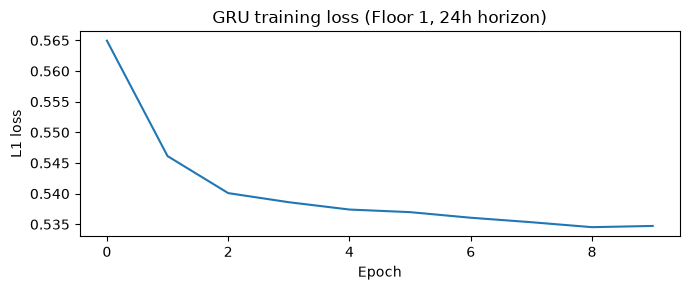

In [ ]:
demo_bundle = train_gru(floor1, horizon_steps=24)
print(demo_bundle["metrics"])

plt.figure(figsize=(7, 3))
plt.plot(demo_bundle["train_losses"])
plt.title("GRU training loss (Floor 1, 24h horizon)")
plt.xlabel("Epoch")
plt.ylabel("L1 loss")
plt.tight_layout()
plt.show()


## 6. XGBoost forecaster

In [ ]:
def train_xgb(df, horizon_steps):
    sup = make_supervised(df, horizon_steps)
    split = max(1, int(len(sup) * 0.85))
    train, val = sup.iloc[:split], sup.iloc[split:]

    model = XGBRegressor(
        n_estimators=250, max_depth=4, learning_rate=0.06,
        subsample=0.85, colsample_bytree=0.85,
        objective="reg:squarederror", random_state=42,
    )
    model.fit(train[FEATURE_COLUMNS], train["target"])

    n_features = len(FEATURE_COLUMNS)
    if len(val) > 0:
        val_pred = model.predict(val[FEATURE_COLUMNS])
        val_true = val["target"].to_numpy()
        metrics = regression_metrics(val_true, val_pred, n_features)
        baseline_metrics = regression_metrics(val_true, val["naive_persistence"].to_numpy(), n_features)
        residual_std = float(np.std(val_true - val_pred))
    else:
        val_pred = val_true = np.array([])
        metrics = regression_metrics(val_true, val_pred, n_features)
        baseline_metrics = metrics
        residual_std = 0.5

    return {"model": model, "explainer": shap.TreeExplainer(model), "metrics": metrics,
            "baseline_metrics": baseline_metrics, "residual_std": residual_std,
            "latest_features": sup.iloc[[-1]][FEATURE_COLUMNS] if len(sup) else None,
            "val_pred": val_pred, "val_true": val_true}


def xgb_predict_latest(bundle, df):
    feat_df = build_features(df)
    latest = feat_df.iloc[[-1]][FEATURE_COLUMNS]
    return float(bundle["model"].predict(latest)[0])


### 6.1 Demo: train XGBoost for Floor 1, 24-hour horizon

{'rmse': 0.18617986282558216, 'mse': 0.03466294132175259, 'mae': 0.12998324037337788, 'mape': 88.59728276108592, 'r2': -0.09695666517679769, 'adj_r2': -0.13167048369505086}


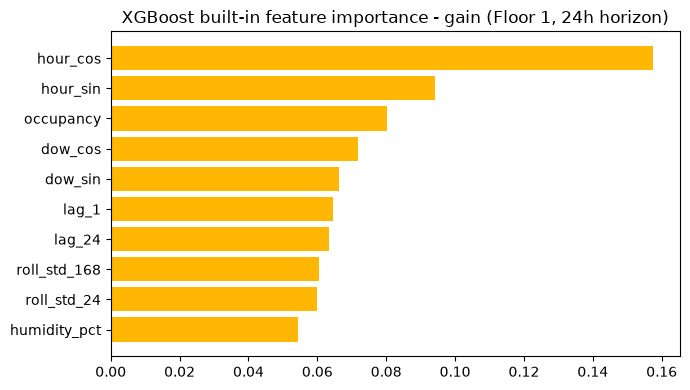

In [ ]:
xgb_demo = train_xgb(floor1, horizon_steps=24)
print(xgb_demo["metrics"])

importances = xgb_demo["model"].feature_importances_
order = np.argsort(importances)[::-1][:10]
plt.figure(figsize=(7, 4))
plt.barh([FEATURE_COLUMNS[i] for i in order][::-1], importances[order][::-1], color="#ffb703")
plt.title("XGBoost built-in feature importance - gain (Floor 1, 24h horizon)")
plt.tight_layout()
plt.show()


### 6.2 SHAP explainability



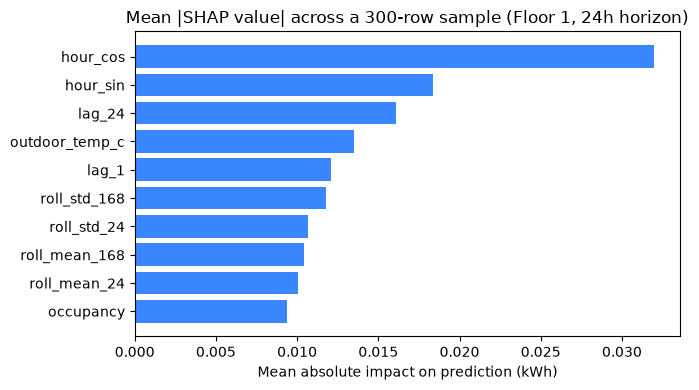

In [ ]:
explainer = xgb_demo["explainer"]
sup = make_supervised(floor1, horizon_steps=24)
sample = sup[FEATURE_COLUMNS].sample(min(300, len(sup)), random_state=42)
shap_values = explainer.shap_values(sample)

mean_abs_shap = np.abs(shap_values).mean(axis=0)
order = np.argsort(mean_abs_shap)[::-1][:10]
plt.figure(figsize=(7, 4))
plt.barh([FEATURE_COLUMNS[i] for i in order][::-1], mean_abs_shap[order][::-1], color="#3a86ff")
plt.title("Mean |SHAP value| across a 300-row sample (Floor 1, 24h horizon)")
plt.xlabel("Mean absolute impact on prediction (kWh)")
plt.tight_layout()
plt.show()


In [ ]:
latest = xgb_demo["latest_features"]
latest_shap = explainer.shap_values(latest)[0]
pairs = sorted(zip(FEATURE_COLUMNS, latest_shap), key=lambda p: abs(p[1]), reverse=True)[:5]

for name, val in pairs:
    direction = "+" if val >= 0 else ""
    print(f"{name:>14}: {direction}{val:.4f} kWh")


outdoor_temp_c: +0.0983 kWh
      hour_sin: +0.0488 kWh
      hour_cos: +0.0429 kWh
  roll_std_168: +0.0298 kWh
        lag_24: +0.0197 kWh


## 7. Ensemble blending



In [ ]:
def train_ensemble(df, horizon_steps):
    gru_bundle = train_gru(df, horizon_steps)
    xgb_bundle = train_xgb(df, horizon_steps)

    gru_rmse = gru_bundle["metrics"]["rmse"] or 1.0
    xgb_rmse = xgb_bundle["metrics"]["rmse"] or 1.0
    inv_gru, inv_xgb = 1.0 / max(gru_rmse, 1e-6), 1.0 / max(xgb_rmse, 1e-6)
    w_gru = inv_gru / (inv_gru + inv_xgb)
    w_xgb = 1.0 - w_gru

    blended_residual_std = float(np.sqrt(
        (w_gru * gru_bundle["residual_std"]) ** 2 + (w_xgb * xgb_bundle["residual_std"]) ** 2
    ))
    blended_metrics = blend_val_predictions(gru_bundle, xgb_bundle, w_gru, w_xgb)

    return {"gru": gru_bundle, "xgb": xgb_bundle, "weights": {"gru": w_gru, "xgb": w_xgb},
            "residual_std": blended_residual_std, "baseline_metrics": xgb_bundle["baseline_metrics"],
            "blended_metrics": blended_metrics}


def blend_val_predictions(gru_bundle, xgb_bundle, w_gru, w_xgb):
    g, x = gru_bundle["metrics"], xgb_bundle["metrics"]
    if g["rmse"] is None or x["rmse"] is None:
        return x or g

    gru_pred, xgb_pred = gru_bundle["val_pred"], xgb_bundle["val_pred"]
    n = min(len(gru_pred), len(xgb_pred))
    if n == 0:
        return x or g

    gru_tail, xgb_tail = gru_pred[-n:], xgb_pred[-n:]
    y_true = xgb_bundle["val_true"][-n:]
    blended_pred = w_gru * gru_tail + w_xgb * xgb_tail
    return regression_metrics(y_true, blended_pred, len(FEATURE_COLUMNS))


def ensemble_predict(bundle, df, z=1.28):
    gru_pred = gru_predict_latest(bundle["gru"], df)
    xgb_pred = xgb_predict_latest(bundle["xgb"], df)
    w = bundle["weights"]
    point = max(0.0, w["gru"] * gru_pred + w["xgb"] * xgb_pred)
    margin = z * bundle["residual_std"]
    naive = float(df.sort_values("ts")["total_kwh"].iloc[-1])
    return {"predicted": round(point, 4), "lower": round(max(0.0, point - margin), 4),
            "upper": round(point + margin, 4), "naive_persistence": round(naive, 4)}


## 8. Anomaly detection — control chart + autoencoder

In [ ]:
CONTROL_CHART_WINDOW = 168
CONTROL_CHART_Z = 3.0
AUTOENCODER_PERCENTILE = 98.5
AE_FEATURES = ["total_kwh"]


class Autoencoder(nn.Module):
    def __init__(self, n_features, latent=3):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_features, 8), nn.ReLU(), nn.Linear(8, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, 8), nn.ReLU(), nn.Linear(8, n_features))

    def forward(self, x):
        return self.decoder(self.encoder(x))


def control_chart_flags(series):
    rolling_mean = series.rolling(CONTROL_CHART_WINDOW, min_periods=24).mean()
    rolling_std = series.rolling(CONTROL_CHART_WINDOW, min_periods=24).std().replace(0, np.nan)
    z = (series - rolling_mean) / rolling_std
    flagged = z.abs() >= CONTROL_CHART_Z
    return pd.DataFrame({"expected": rolling_mean, "z_score": z, "flagged": flagged.fillna(False)})


def train_autoencoder(df, control_flags, epochs=30):
    data = df[AE_FEATURES].to_numpy(dtype=np.float32)
    normal_mask = ~control_flags.fillna(False).to_numpy()
    normal_data = data[normal_mask] if normal_mask.sum() > 20 else data
    mean, std = normal_data.mean(axis=0), normal_data.std(axis=0)
    std[std == 0] = 1.0
    x = torch.from_numpy(((normal_data - mean) / std).astype(np.float32))

    torch.manual_seed(42)
    model = Autoencoder(n_features=len(AE_FEATURES))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()
    model.train()
    for _ in range(epochs):
        opt.zero_grad()
        loss = loss_fn(model(x), x)
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        all_scaled = torch.from_numpy(((data - mean) / std).astype(np.float32))
        recon = model(all_scaled).numpy()
    errors = np.mean((((data - mean) / std) - recon) ** 2, axis=1)
    threshold = float(np.percentile(errors, AUTOENCODER_PERCENTILE))
    return {"model": model, "mean": mean, "std": std, "threshold": threshold, "errors": errors}


def detect(df):
    data = df.sort_values("ts").reset_index(drop=True)
    cc = control_chart_flags(data["total_kwh"])
    ae = train_autoencoder(data, cc["flagged"])
    ae_flag = ae["errors"] >= ae["threshold"]

    result = data[["ts", "floor", "total_kwh"]].copy()
    result["control_chart_flag"] = cc["flagged"]
    result["autoencoder_flag"] = ae_flag
    result["is_anomaly"] = result["control_chart_flag"] | result["autoencoder_flag"]
    return result


def evaluate_detection(df, injection_rate=0.02, injection_multiplier=3.5, seed=42):
    data = df.sort_values("ts").reset_index(drop=True).copy()
    n = len(data)
    rng = np.random.default_rng(seed)
    n_inject = min(max(3, int(n * injection_rate)), n)
    inject_idx = rng.choice(n, size=n_inject, replace=False)

    injected = data.copy()
    ground_truth = np.zeros(n, dtype=bool)
    for idx in inject_idx:
        injected.loc[idx, "total_kwh"] = injected.loc[idx, "total_kwh"] * injection_multiplier + 0.5
        ground_truth[idx] = True

    predicted = detect(injected)["is_anomaly"].to_numpy()
    tp = int(np.sum(predicted & ground_truth))
    fp = int(np.sum(predicted & ~ground_truth))
    fn = int(np.sum(~predicted & ground_truth))
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"n_injected": int(ground_truth.sum()), "true_positives": tp, "false_positives": fp,
            "false_negatives": fn, "precision": round(precision, 4), "recall": round(recall, 4), "f1": round(f1, 4)}


### 8.1 Demo: anomaly detection evaluation for Floor 1

In [ ]:
eval_demo = evaluate_detection(floor1)
eval_demo


{'n_injected': 65,
 'true_positives': 50,
 'false_positives': 39,
 'false_negatives': 15,
 'precision': 0.5618,
 'recall': 0.7692,
 'f1': 0.6494}

## 9. Full training run — every floor, every horizon



In [ ]:
HORIZONS = {"1h": 1, "24h": 24, "7d": 168}
results = []
anomaly_results = []

for floor in ZONES:
    floor_df = readings[readings["floor"] == floor]
    for horizon_name, steps in HORIZONS.items():
        bundle = train_ensemble(floor_df, steps)
        m = bundle["blended_metrics"]
        results.append({
            "floor": floor, "horizon": horizon_name,
            "persistence_rmse": bundle["baseline_metrics"]["rmse"],
            "persistence_mae": bundle["baseline_metrics"]["mae"],
            "gru_rmse": bundle["gru"]["metrics"]["rmse"], "gru_mae": bundle["gru"]["metrics"]["mae"],
            "gru_r2": bundle["gru"]["metrics"]["r2"],
            "xgb_rmse": bundle["xgb"]["metrics"]["rmse"], "xgb_mae": bundle["xgb"]["metrics"]["mae"],
            "xgb_r2": bundle["xgb"]["metrics"]["r2"],
            "rmse": m["rmse"], "mse": m["mse"], "mae": m["mae"], "mape": m["mape"],
            "r2": m["r2"], "adj_r2": m["adj_r2"],
            "baseline_rmse": bundle["baseline_metrics"]["rmse"],
        })
        print(f"floor {floor}  {horizon_name:>3}  persistence={bundle['baseline_metrics']['rmse']:.4f}  "
              f"GRU={bundle['gru']['metrics']['rmse']:.4f}  XGB={bundle['xgb']['metrics']['rmse']:.4f}  "
              f"ensemble={m['rmse']:.4f}")
    anomaly_results.append({"floor": floor, **evaluate_detection(floor_df)})

results_df = pd.DataFrame(results)
anomaly_df = pd.DataFrame(anomaly_results)
results_df


floor 1   1h  persistence=0.1382  GRU=0.1637  XGB=0.1610  ensemble=0.1449


floor 1  24h  persistence=0.2252  GRU=0.1804  XGB=0.1862  ensemble=0.1683


floor 1   7d  persistence=0.2067  GRU=0.1887  XGB=0.1680  ensemble=0.1704


floor 2   1h  persistence=0.0828  GRU=0.0996  XGB=0.0912  ensemble=0.0790


floor 2  24h  persistence=0.1382  GRU=0.1151  XGB=0.1541  ensemble=0.1128


...

floor 3   7d  persistence=0.1215  GRU=0.1062  XGB=0.1125  ensemble=0.1010


floor 4   1h  persistence=0.0848  GRU=0.0851  XGB=0.1164  ensemble=0.0807


floor 4  24h  persistence=0.1088  GRU=0.0890  XGB=0.1222  ensemble=0.0907


floor 4   7d  persistence=0.1088  GRU=0.0935  XGB=0.0941  ensemble=0.0880


,floor,horizon,persistence_rmse,persistence_mae,gru_rmse,gru_mae,gru_r2,xgb_rmse,xgb_mae,xgb_r2,rmse,mse,mae,mape,r2,adj_r2,baseline_rmse
0,1,1h,0.138164,0.073447,0.163710,0.082161,0.155105,0.161035,0.114782,0.175510,0.144909,0.020998,0.087738,49.361214,0.338030,0.316767,0.138164
1,1,24h,0.225236,0.131033,0.180405,0.096707,-0.025453,0.186180,0.129983,-0.096957,0.168255,0.028310,0.104809,64.986557,0.108017,0.079182,0.225236
2,1,7d,0.206725,0.117455,0.188739,0.097185,-0.085147,0.167964,0.100139,0.126497,0.170391,0.029033,0.091132,46.804316,0.115577,0.085563,0.206725
3,2,1h,0.082827,0.042329,0.099574,0.051084,0.231018,0.091241,0.054048,0.342972,0.078995,0.006240,0.044156,48.602172,0.516024,0.500479,0.082827
4,2,24h,0.138190,0.079410,0.115109,0.059354,-0.025642,0.154062,0.108101,-0.861476,0.112776,0.012718,0.070073,93.000384,0.015518,-0.016308,0.138190
5,2,7d,0.124145,0.071257,0.122017,0.063130,-0.115855,0.110818,0.068058,0.064378,0.110712,0.012257,0.060471,64.155842,0.081322,0.050145,0.124145
6,3,1h,0.105163,0.062463,0.105913,0.063609,0.190093,0.120847,0.083469,-0.033175,0.093858,0.008809,0.062011,45.274483,0.363972,0.343543,0.105163
7,3,24h,0.130059,0.087586,0.112914,0.071319,0.067121,0.154821,0.115624,-0.687939,0.107914,0.011645,0.077138,65.511149,0.147921,0.120375,0.130059
8,3,7d,0.121453,0.082227,0.106215,0.072021,0.189847,0.112502,0.080018,0.085824,0.100984,0.010198,0.071433,56.499656,0.267673,0.242821,0.121453
9,4,1h,0.084825,0.045814,0.085081,0.049693,0.196709,0.116395,0.078483,-0.529679,0.080673,0.006508,0.053496,59.703653,0.277786,0.254589,0.084825


In [ ]:
anomaly_df


,floor,n_injected,true_positives,false_positives,false_negatives,precision,recall,f1
0,1,65,50,39,15,0.5618,0.7692,0.6494
1,2,65,48,48,17,0.5000,0.7385,0.5963
2,3,65,38,51,27,0.4270,0.5846,0.4935
3,4,65,55,32,10,0.6322,0.8462,0.7237


### 9.1 Model comparison - E0 (persistence) vs E4 (GRU alone) vs E3 (XGBoost alone) vs E5 (ensemble)


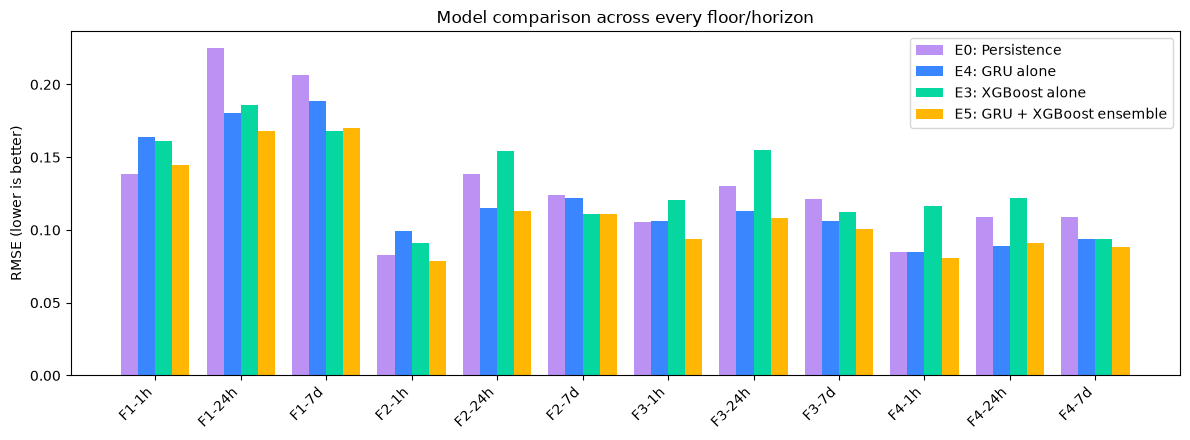

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.5))
width = 0.2
x = np.arange(len(results_df))
ax.bar(x - 1.5 * width, results_df["persistence_rmse"], width, label="E0: Persistence", color="#8338ec", alpha=0.55)
ax.bar(x - 0.5 * width, results_df["gru_rmse"], width, label="E4: GRU alone", color="#3a86ff")
ax.bar(x + 0.5 * width, results_df["xgb_rmse"], width, label="E3: XGBoost alone", color="#06d6a0")
ax.bar(x + 1.5 * width, results_df["rmse"], width, label="E5: GRU + XGBoost ensemble", color="#ffb703")
ax.set_xticks(x)
ax.set_xticklabels([f"F{r.floor}-{r.horizon}" for r in results_df.itertuples()], rotation=45, ha="right")
ax.set_ylabel("RMSE (lower is better)")
ax.set_title("Model comparison across every floor/horizon")
ax.legend()
plt.tight_layout()
plt.show()


## 10. Occupancy ablation

In [ ]:
ablation_variants = {
    "A: Temp + Occupancy": ["total_kwh", "outdoor_temp_c", "occupancy"],
    "B: Occupancy only": ["total_kwh", "occupancy"],
    "C: Temperature only": ["total_kwh", "outdoor_temp_c"],
}

ablation_results = []
for variant_name, feats in ablation_variants.items():
    for floor in ZONES:
        floor_df = readings[readings["floor"] == floor]
        bundle = train_gru(floor_df, horizon_steps=1, seq_features=feats)
        ablation_results.append({"variant": variant_name, "floor": floor, **bundle["metrics"]})

ablation_df = pd.DataFrame(ablation_results)
ablation_summary = ablation_df.groupby("variant")[["rmse", "mse", "mae", "mape", "r2", "adj_r2"]].mean()
ablation_summary = ablation_summary.reindex(list(ablation_variants.keys()))
ablation_summary


,rmse,mse,mae,mape,r2,adj_r2
variant,,,,,,
A: Temp + Occupancy,0.113570,0.013793,0.061637,40.285717,0.193231,0.188178
B: Occupancy only,0.114520,0.014002,0.062559,41.599976,0.177551,0.174124
C: Temperature only,0.112433,0.013487,0.062691,44.956721,0.207721,0.204420


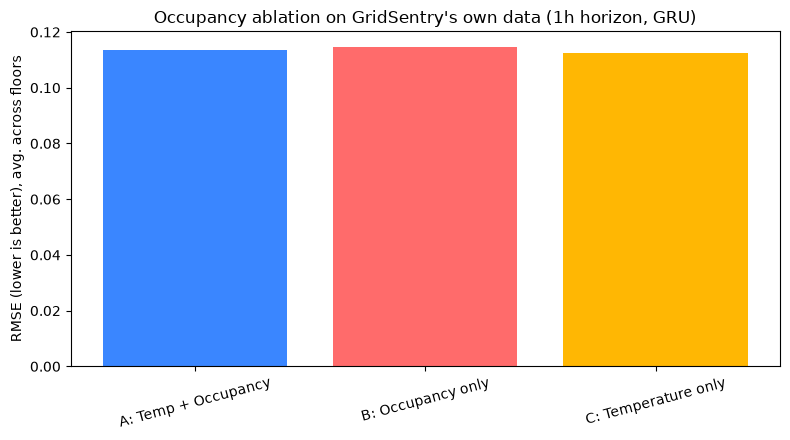

Adding occupancy to temperature worsens RMSE by 1.0% on GridSentry's own data (paper's equivalent A-vs-C comparison: 13.0% improvement).


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#3a86ff", "#ff6b6b", "#ffb703"]
ax.bar(ablation_summary.index, ablation_summary["rmse"], color=colors)
ax.set_ylabel("RMSE (lower is better), avg. across floors")
ax.set_title("Occupancy ablation on GridSentry's own data (1h horizon, GRU)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

rmse_a = ablation_summary.loc["A: Temp + Occupancy", "rmse"]
rmse_c = ablation_summary.loc["C: Temperature only", "rmse"]
change = (rmse_c - rmse_a) / rmse_c * 100
direction = "improves" if change > 0 else "worsens"
print(f"Adding occupancy to temperature {direction} RMSE by {abs(change):.1f}% on GridSentry's own data "
      f"(paper's equivalent A-vs-C comparison: 13.0% improvement).")


## 11. Comparison with the base paper (Anan et al., 2024)

The base paper's Table 8 reports RMSE, MSE, R², adjusted R², MAE, and MAPE for three LSTM
variants trained on its own Houston office-building dataset: Model A (outdoor temperature +
occupancy), Model B (occupancy only), and Model C (temperature only). Values below are transcribed
directly from the published table. GridSentry's row is the 1-hour-horizon ensemble result computed
above, averaged across all four floors.

In [ ]:
base_paper = pd.DataFrame([
    {"model": "Model A (Temp + Occupancy)", "rmse": 0.25374, "mse": 0.06438, "mae": 0.09306, "mape": 0.04135, "r2": 0.98901, "adj_r2": 0.98899},
    {"model": "Model B (Occupancy only)", "rmse": 0.36216, "mse": 0.13116, "mae": 0.21339, "mape": 0.10975, "r2": 0.97762, "adj_r2": 0.97757},
    {"model": "Model C (Temperature only)", "rmse": 0.29156, "mse": 0.08501, "mae": 0.15018, "mape": 0.07802, "r2": 0.98549, "adj_r2": 0.98546},
]).set_index("model")

hourly_results = results_df[results_df["horizon"] == "1h"]
gridsentry_row = pd.Series(
    {k: hourly_results[k].mean() for k in ["rmse", "mse", "mae", "mape", "r2", "adj_r2"]},
    name="GridSentry (ensemble, 1h, avg. across floors)",
)

comparison = pd.concat([base_paper, gridsentry_row.to_frame().T])
comparison


,rmse,mse,mae,mape,r2,adj_r2
Model A (Temp + Occupancy),0.253740,0.064380,0.09306,0.041350,0.989010,0.988990
Model B (Occupancy only),0.362160,0.131160,0.21339,0.109750,0.977620,0.977570
Model C (Temperature only),0.291560,0.085010,0.15018,0.078020,0.985490,0.985460
"GridSentry (ensemble, 1h, avg. across floors)",0.099609,0.010639,0.06185,50.735381,0.373953,0.353844


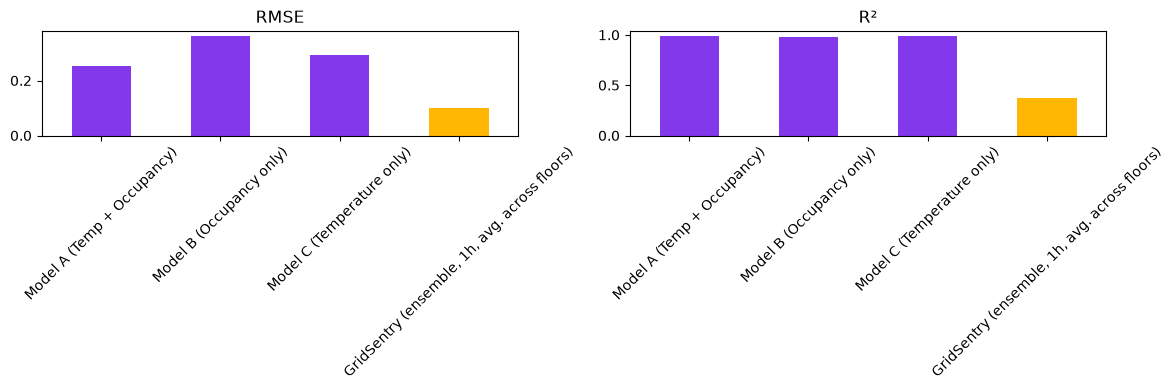

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison["rmse"].plot(kind="bar", ax=axes[0], color=["#8338ec", "#8338ec", "#8338ec", "#ffb703"])
axes[0].set_title("RMSE")
axes[0].tick_params(axis="x", rotation=45)

comparison["r2"].plot(kind="bar", ax=axes[1], color=["#8338ec", "#8338ec", "#8338ec", "#ffb703"])
axes[1].set_title("R\u00b2")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 12. Forecasting the real, un-split building total



In [ ]:
building_total = (
    readings.groupby("ts")
    .agg(total_kwh=("total_kwh", "sum"), outdoor_temp_c=("outdoor_temp_c", "first"), humidity_pct=("humidity_pct", "first"))
    .reset_index()
)
building_total["occupancy"] = (building_total["total_kwh"].rank(pct=True) * 6).round().astype(int)
building_total["floor"] = 0

print(building_total.shape)
building_total.head()


(3290, 6)


,ts,total_kwh,outdoor_temp_c,humidity_pct,occupancy,floor
0,2016-01-11 17:00:00,0.5400,6.31,92.0,4,0
1,2016-01-11 18:00:00,1.3700,5.94,91.6,5,0
2,2016-01-11 19:00:00,1.1900,6.00,89.8,5,0
3,2016-01-11 20:00:00,0.9601,6.00,87.6,5,0
4,2016-01-11 21:00:00,0.7601,5.83,87.4,5,0


In [ ]:
building_bundle = train_ensemble(building_total, horizon_steps=1)
building_metrics = building_bundle["blended_metrics"]
print(building_metrics)

building_row = pd.Series(building_metrics, name="GridSentry (whole-building total, 1h, real signal)")
fair_comparison = pd.concat([comparison, building_row.to_frame().T])
fair_comparison


{'rmse': 0.3249764278197709, 'mse': 0.10560967863849874, 'mae': 0.1805406572477171, 'mape': 25.934975943930976, 'r2': 0.43301985864685033, 'adj_r2': 0.41480850507019673}


,rmse,mse,mae,mape,r2,adj_r2
Model A (Temp + Occupancy),0.253740,0.064380,0.093060,0.041350,0.989010,0.988990
Model B (Occupancy only),0.362160,0.131160,0.213390,0.109750,0.977620,0.977570
Model C (Temperature only),0.291560,0.085010,0.150180,0.078020,0.985490,0.985460
"GridSentry (ensemble, 1h, avg. across floors)",0.099609,0.010639,0.061850,50.735381,0.373953,0.353844
"GridSentry (whole-building total, 1h, real signal)",0.324976,0.105610,0.180541,25.934976,0.433020,0.414809


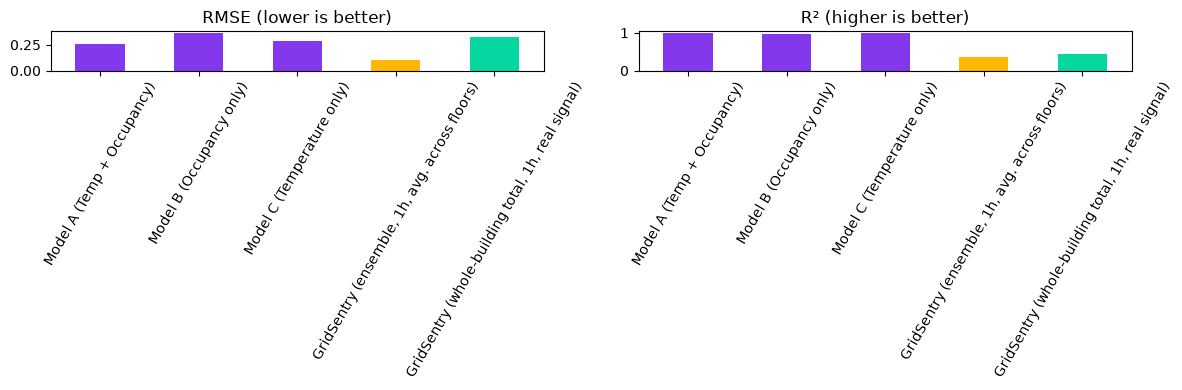

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#8338ec", "#8338ec", "#8338ec", "#ffb703", "#06d6a0"]
fair_comparison["rmse"].plot(kind="bar", ax=axes[0], color=colors)
axes[0].set_title("RMSE (lower is better)")
axes[0].tick_params(axis="x", rotation=60)

fair_comparison["r2"].plot(kind="bar", ax=axes[1], color=colors)
axes[1].set_title("R\u00b2 (higher is better)")
axes[1].axhline(0, color="#666", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()


## 13. Mini hyperparameter study



In [ ]:
lookback_trials = [24, 72, 168]
lookback_results = []
for lb in lookback_trials:
    b = train_gru(floor1, horizon_steps=1, lookback=lb)
    lookback_results.append({"lookback": lb, "rmse": b["metrics"]["rmse"], "r2": b["metrics"]["r2"]})
lookback_df = pd.DataFrame(lookback_results)
lookback_df


,lookback,rmse,r2
0,24,0.16191,0.170391
1,72,0.16371,0.155105
2,168,0.16513,0.155724


In [ ]:
hidden_trials = [16, 32, 64]
hidden_results = []
for hs in hidden_trials:
    data = floor1.sort_values("ts").reset_index(drop=True)
    raw = data[SEQ_FEATURES].to_numpy(dtype=np.float32)
    target_series = data["total_kwh"].shift(-1).to_numpy(dtype=np.float32)
    valid_len = len(raw) - 1
    raw, target_series = raw[:valid_len], target_series[:valid_len]
    mean, std = raw.mean(axis=0), raw.std(axis=0)
    std[std == 0] = 1.0
    scaler_hs = ScalerStats(mean=mean, std=std)
    scaled = scaler_hs.transform(raw)
    target_scaled = (target_series - mean[0]) / std[0]
    X, y = build_sequences(scaled, target_scaled, 72)
    split = max(1, int(len(X) * 0.85))
    X_train_t, y_train_t = torch.from_numpy(X[:split]), torch.from_numpy(y[:split])
    X_val, y_val = X[split:], y[split:]

    torch.manual_seed(42)
    model_hs = GRUForecaster(n_features=len(SEQ_FEATURES), hidden_size=hs)
    opt = torch.optim.Adam(model_hs.parameters(), lr=1e-3)
    loss_fn = nn.L1Loss()
    model_hs.train()
    n = len(X_train_t)
    for _ in range(10):
        perm = torch.randperm(n)
        for start in range(0, n, 64):
            idx = perm[start:start + 64]
            opt.zero_grad()
            loss = loss_fn(model_hs(X_train_t[idx]), y_train_t[idx])
            loss.backward()
            opt.step()

    model_hs.eval()
    with torch.no_grad():
        val_pred = scaler_hs.inverse_target(model_hs(torch.from_numpy(X_val)).numpy())
        val_true = scaler_hs.inverse_target(y_val)
    m = regression_metrics(val_true, val_pred, len(SEQ_FEATURES))
    hidden_results.append({"hidden_size": hs, "rmse": m["rmse"], "r2": m["r2"]})

hidden_df = pd.DataFrame(hidden_results)
hidden_df


,hidden_size,rmse,r2
0,16,0.162214,0.170481
1,32,0.163710,0.155105
2,64,0.160666,0.186239


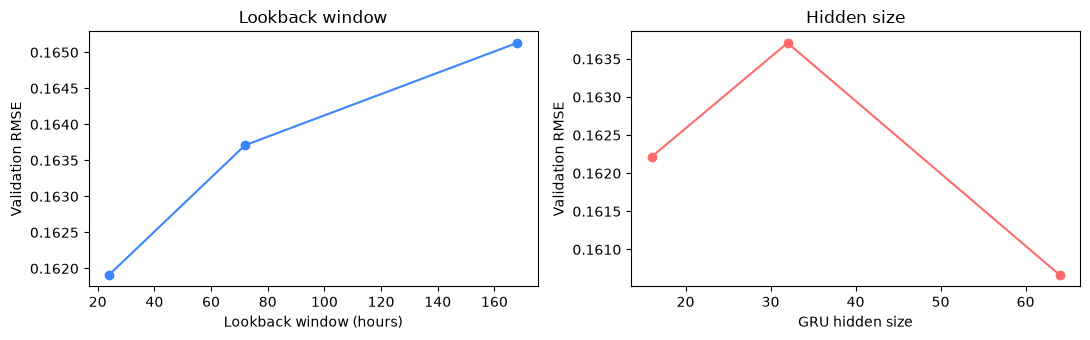

Best lookback: 24h (val RMSE 0.1619)
Best hidden size: 64 (val RMSE 0.1607)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(lookback_df["lookback"], lookback_df["rmse"], marker="o", color="#3a86ff")
axes[0].set_xlabel("Lookback window (hours)")
axes[0].set_ylabel("Validation RMSE")
axes[0].set_title("Lookback window")

axes[1].plot(hidden_df["hidden_size"], hidden_df["rmse"], marker="o", color="#ff6b6b")
axes[1].set_xlabel("GRU hidden size")
axes[1].set_ylabel("Validation RMSE")
axes[1].set_title("Hidden size")
plt.tight_layout()
plt.show()

best_lookback = lookback_df.loc[lookback_df["rmse"].idxmin()]
best_hidden = hidden_df.loc[hidden_df["rmse"].idxmin()]
print(f"Best lookback: {int(best_lookback['lookback'])}h (val RMSE {best_lookback['rmse']:.4f})")
print(f"Best hidden size: {int(best_hidden['hidden_size'])} (val RMSE {best_hidden['rmse']:.4f})")
